# Catching SMS Spam with Naive Bayes

**CS 5830 · Project 5** · Abinash Pant · October 2026

Can a Naive Bayes classifier tell a scam text (*"URGENT! You have won a £1,000 prize, call 0906…"*) from an ordinary one (*"ok see u at 5"*)? This notebook builds and tests Naive Bayes spam filters on the public **UCI SMS Spam Collection** and compares the two event models the project asks about: **multinomial** Naive Bayes on the words of a message and **Gaussian** Naive Bayes on numeric statistics of the message, plus a hybrid that uses both.

| Section | What happens |
|---|---|
| 1. Data | Load 5,574 labelled messages; fix encoding; remove duplicates and a corpus artifact; split train/test |
| 2. Exploration | What separates spam from ham |
| 3. Method | How Naive Bayes works, multinomial vs Gaussian, the hybrid, and a from-scratch check |
| 4. Training | Tune every model with 5-fold cross-validation on the training set only |
| 5. Results | Test scores, confusion matrices, the words that flag spam, threshold choice, errors, learning curve, assumption checks |
| 6. Conclusions | Answers to the research questions, limitations, next steps |

**Research questions.** RQ1: how well does Naive Bayes separate spam from ham on messages it has never seen? RQ2: which event model fits which features (multinomial on word counts or Gaussian on numeric statistics), and does combining them help? RQ3: what gives spam away, and which errors remain?

Running the notebook top to bottom reproduces every number in the report and slides (random seed 5830).

In [30]:
import csv
import html
import io
import json
import re
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.special import expit, logsumexp
from scipy.stats import skew, spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, learning_curve, train_test_split
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 5830
DATA_DIR, FIG_DIR, RESULTS_DIR = Path("data/sms_spam_collection"), Path("figures"), Path("results")
for folder in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.precision", 3)

In [31]:
# Chart style, used by every figure. In class charts ham is blue and spam orange; in model charts each
# model keeps one colour (slots 1-4 of a colour-blind-checked palette). Grids are solid hairlines.
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, GREY = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#c3c2b7"
HAM, SPAM = "#2a78d6", "#eb6834"
MODEL_COLOUR = {"bnb": "#2a78d6", "mnb": "#eb6834", "gnb_stats": "#1baf7a", "logreg": "#eda100"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10.5,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.titlepad": 10, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "legend.labelcolor": INK_2, "legend.fontsize": 10,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def pixel_size(ax):
    # Data units per screen pixel along x and y, so details can be drawn at a fixed pixel size.
    ax.figure.canvas.draw()
    (x0, y0), (x1, y1) = ax.transData.inverted().transform([(0, 0), (1, 1)])
    return abs(x1 - x0), abs(y1 - y0)


def hbar(ax, y, start, end, colour, unit, thickness_px=16, round_end=True):
    # Horizontal bar from `start` to `end`: square at the baseline, 4px-rounded at the data end.
    ux, uy = unit
    h, lo, hi = thickness_px * uy, min(start, end), max(start, end)
    r = min(4 * ux, (hi - lo) / 2) if round_end else 0.0
    style = f"round,pad=0,rounding_size={r}" if r > 0 else "square,pad=0"
    ax.add_patch(FancyBboxPatch((lo, y - h / 2), hi - lo, h, boxstyle=style, mutation_aspect=uy / ux,
                                linewidth=0, facecolor=colour))
    if r > 0:  # square the baseline end again
        ax.add_patch(Rectangle((lo if end >= start else hi - r, y - h / 2), r, h, linewidth=0, facecolor=colour))


def save(fig, name):
    fig.savefig(FIG_DIR / name)
    plt.show()

## 1. Data

The [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (Almeida, Gómez Hidalgo & Yamakami, 2011) is hosted by the UCI Machine Learning Repository. It merges four public sources:

| Source | Ham | Spam |
|---|---:|---:|
| Grumbletext, a UK forum where people post spam texts they received | | 425 |
| NUS SMS Corpus (mostly students at the National University of Singapore) | 3,375 | |
| Caroline Tagg's PhD thesis corpus | 450 | |
| SMS Spam Corpus v0.1 Big | 1,002 | 322 |
| **Total** | **4,827** | **747** |

Each line of the file is a label (`ham` = legitimate, `spam`) and the raw message text.

In [32]:
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
raw_file = DATA_DIR / "SMSSpamCollection"
if not raw_file.exists():  # download once and read only the data file out of the archive
    with urllib.request.urlopen(URL, timeout=60) as response:
        with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
            raw_file.write_bytes(archive.read("SMSSpamCollection"))

raw = pd.read_csv(raw_file, sep="\t", header=None, names=["label", "text"],
                  quoting=csv.QUOTE_NONE, encoding="utf-8")
print(f"{len(raw):,} messages")
raw["label"].value_counts().to_frame("messages").assign(share=lambda d: d["messages"] / d["messages"].sum())

5,574 messages


,messages,share
label,,
ham,4827,0.866
spam,747,0.134


### 1.1 Cleaning

The raw file has four problems. Each is fixed below, and the last two matter more than they look:

1. **Broken characters.** HTML entities (`&lt;`, `&gt;`, `&amp;`) and Windows-1252 punctuation decoded as control codes (`\x92` instead of an apostrophe). → Unescape them and map them to plain ASCII.
2. **Duplicates.** Chain messages and spam templates appear many times. A message that sits in both the training and the test set measures memory, not generalisation. → Keep one copy of each (label, text) pair.
3. **A ham-only artifact.** The NUS corpus hid numbers, times and links behind placeholders such as `<#>` and `<DECIMAL>`. Those never occur in spam, so a model would learn "`<#>` means ham", a rule that is useless on a real phone. → Map them to the same token as real numbers.
4. **Numbers are too specific.** Every spam has a different phone number, so raw digits rarely repeat. → Replace phone numbers, money amounts, links and long numbers with category tokens, so the model learns "contains a phone number".

In [33]:
CHARACTER_FIXES = {
    "\x91": "'", "\x92": "'", "\x93": '"', "\x94": '"', "\x96": "-", "\x97": "-", "\x85": "...",
    "‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-", "…": "...",
}


def fix_text(text):
    # Undo HTML escaping and Windows-1252 mis-decoding, then collapse runs of whitespace.
    text = html.unescape(text)
    for bad, good in CHARACTER_FIXES.items():
        text = text.replace(bad, good)
    return " ".join(text.split())


fixed = raw.assign(text=raw["text"].map(fix_text))
print("Messages changed by the character fix:", int((fixed["text"] != raw["text"]).sum()))
print("Exact duplicates in the raw file:     ", int(raw.duplicated().sum()))

duplicate = fixed.duplicated(["label", "text"], keep="first")
conflicting = int(fixed.groupby("text")["label"].nunique().gt(1).sum())
print("Duplicates after the character fix:   ", int(duplicate.sum()), duplicate.groupby(fixed["label"]).sum().to_dict())
print("Texts labelled both ham and spam:     ", conflicting)

sms = fixed.loc[~duplicate].reset_index(drop=True)
sms["spam"] = (sms["label"] == "spam").astype(int)
print(f"\nClean dataset: {len(sms):,} unique messages, {sms['spam'].sum()} spam ({sms['spam'].mean():.1%})")

Messages changed by the character fix: 601
Exact duplicates in the raw file:      403
Duplicates after the character fix:    415 {'ham': 309, 'spam': 106}
Texts labelled both ham and spam:      0

Clean dataset: 5,159 unique messages, 641 spam (12.4%)


In [34]:
# Which anonymisation placeholders occur in which class?
found = [(token, label) for text, label in zip(sms["text"], sms["label"])
         for token in re.findall(r"<(?:#|DECIMAL|TIME|URL|EMAIL|UKP)>", text)]
pd.DataFrame(found, columns=["placeholder", "label"]).value_counts().unstack(fill_value=0)

label,ham,spam
placeholder,,
<#>,254,0
<URL>,2,0
<DECIMAL>,18,0
<TIME>,6,0
<EMAIL>,1,0
<UKP>,0,1


Every placeholder except one `<UKP>` (pounds) sits in ham: 197 ham messages contain `<#>`, no spam does. Left alone, it would be one of the strongest "ham" words in the vocabulary (Section 5.9 measures this).

**Normalising the text.** Next, each message is lower-cased and its links, e-mail addresses, money amounts, phone numbers (UK numbers and 5-digit short codes) and numbers of three or more digits are replaced with category tokens. One- and two-digit numbers stay as words, because in SMS slang they are often words ("2" for *to*, "4" for *for*). The placeholders map to the same tokens. Section 4 checks whether this changes accuracy; its main job is robustness, since the model can now recognise phone numbers it never saw in training.

**Numeric statistics.** For Gaussian Naive Bayes we also compute eight numbers per message from the cleaned (not normalised) text.

In [35]:
TOKEN_RULES = [  # applied in order, most specific first
    (r"<url>|https?://\S+|www\.\S+|\b[\w.-]+\.(?:com|net|org|biz|co\.uk)\b\S*", " urltoken "),
    (r"<email>|\b[\w.+-]+@[\w-]+\.[\w.]+\b", " emailtoken "),
    (r"<ukp>|[£$€]\s?\d[\d,.]*|\b\d+(?:\.\d+)?p\b", " moneytoken "),
    (r"(?<!\d)(?:\+?44|0)\d(?:[\s-]?\d){8,10}(?!\d)|(?<!\d)\d{5}(?!\d)", " phonetoken "),
    (r"<#>|<decimal>|<time>|\d{3,}", " numtoken "),
]
PLACEHOLDER = r"<(?:#|DECIMAL|TIME|URL|EMAIL|UKP)>"


def normalise(text):
    # Lower-case, then swap links, e-mails, money, phone numbers and long numbers for category tokens.
    text = text.lower()
    for pattern, token in TOKEN_RULES:
        text = re.sub(pattern, token, text)
    return " ".join(text.split())


NUMERIC = ["characters", "words", "mean_word_length", "digits", "uppercase_share",
           "exclamations", "currency_symbols", "links"]


def message_statistics(text):
    # Eight numeric features of one message. Placeholders count as one hidden number, link or pound sign.
    plain = re.sub(PLACEHOLDER, " ", text)
    words, letters = plain.split(), [c for c in plain if c.isalpha()]
    return {
        "characters": len(text),
        "words": len(words),
        "mean_word_length": float(np.mean([len(w) for w in words])) if words else 0.0,
        "digits": sum(c.isdigit() for c in plain) + len(re.findall(r"<(?:#|DECIMAL|TIME)>", text)),
        "uppercase_share": sum(c.isupper() for c in letters) / max(len(letters), 1),
        "exclamations": plain.count("!"),
        "currency_symbols": sum(plain.count(s) for s in "£$€") + text.count("<UKP>"),
        "links": len(re.findall(r"https?://|www\.", plain)) + text.count("<URL>"),
    }


data = pd.concat([sms, sms["text"].map(normalise).rename("clean_text"),
                  pd.DataFrame(sms["text"].map(message_statistics).tolist())], axis=1)
data.loc[[2, 8, 9], ["label", "text", "clean_text"]]

,label,text,clean_text
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry ques...,free entry in 2 a wkly comp to win fa cup final tkts 21st may numtoken . text fa to phonetoken to receive ...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call ...,winner!! as a valued network customer you have been selected to receivea moneytoken prize reward! to claim...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Fre...,had your mobile 11 months or more? u r entitled to update to the latest colour mobiles with camera for fre...


In [36]:
# Hold out 20% as a test set, stratified so both parts keep the 13% spam rate.
# The test set is not touched again until Section 5.
train, test = train_test_split(data, test_size=0.2, stratify=data["spam"], random_state=SEED)
X_train, X_test = train[["clean_text"] + NUMERIC], test[["clean_text"] + NUMERIC]
y_train, y_test = train["spam"].to_numpy(), test["spam"].to_numpy()
print(f"Training set: {len(train):,} messages, {y_train.sum()} spam")
print(f"Test set:     {len(test):,} messages, {y_test.sum()} spam")

Training set: 4,127 messages, 513 spam
Test set:     1,032 messages, 128 spam


## 2. Exploration

Exploration uses the cleaned dataset for the class counts and the **training set only** for everything about features, so nothing about the test set leaks into modelling choices.

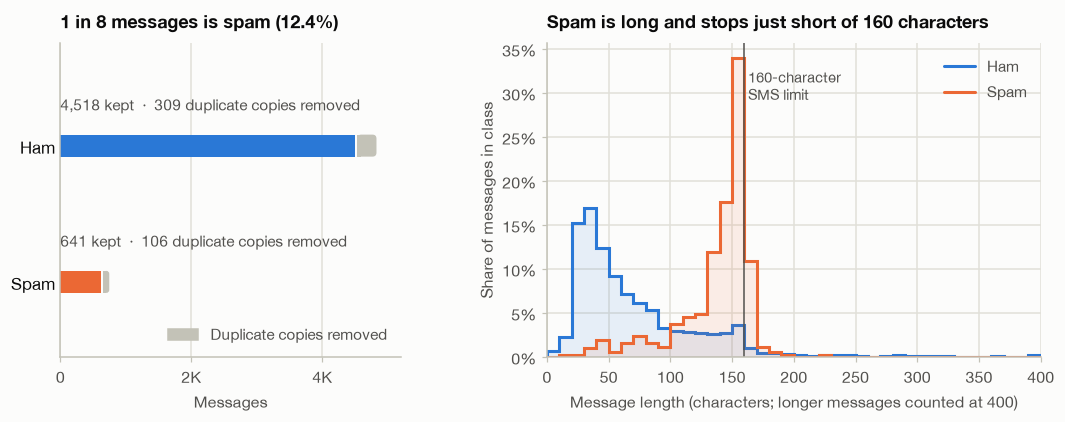

In [37]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw={"width_ratios": [1, 1.45], "wspace": 0.35})

# Left: unique messages kept and duplicate copies removed, per class
kept = sms["label"].value_counts().reindex(["ham", "spam"])
removed = duplicate.groupby(fixed["label"]).sum().reindex(["ham", "spam"])
left.set_xlim(0, 5200); left.set_ylim(-0.75, 1.55); left.invert_yaxis()
unit = pixel_size(left)
gap = 2 * unit[0]
for row, (label, colour) in enumerate([("ham", HAM), ("spam", SPAM)]):
    hbar(left, row, 0, kept[label] - gap / 2, colour, unit, thickness_px=22, round_end=False)
    hbar(left, row, kept[label] + gap / 2, kept[label] + removed[label], GREY, unit, thickness_px=22)
    left.text(0, row - 0.3, f"{kept[label]:,} kept  ·  {removed[label]} duplicate copies removed",
              va="center", color=INK_2, fontsize=10)
left.set_yticks([0, 1], ["Ham", "Spam"]); left.tick_params(axis="y", length=0, labelsize=11, labelcolor=INK)
left.grid(axis="y", visible=False); left.set_xlabel("Messages")
left.set_xticks([0, 2000, 4000], ["0", "2K", "4K"])
left.set_title(f"1 in 8 messages is spam ({sms['spam'].mean():.1%})")
left.legend(handles=[Rectangle((0, 0), 1, 1, color=GREY)], labels=["Duplicate copies removed"], loc="lower right")

# Right: message length by class, as a share of each class
bins = np.arange(0, 401, 10)
for label, colour in [("ham", HAM), ("spam", SPAM)]:
    lengths = train.loc[train["label"] == label, "characters"].clip(upper=400)
    share, _ = np.histogram(lengths, bins=bins)
    share = share / share.sum()
    right.stairs(share, bins, color=colour, linewidth=2, label=label.capitalize())
    right.stairs(share, bins, color=colour, alpha=0.10, fill=True)
right.axvline(160, color=INK_2, linewidth=1)
right.text(163, right.get_ylim()[1] * 0.92, "160-character\nSMS limit", color=INK_2, fontsize=9.5, va="top")
right.set_xlim(0, 400); right.set_xlabel("Message length (characters; longer messages counted at 400)")
right.set_ylabel("Share of messages in class")
right.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
right.set_title("Spam is long and stops just short of 160 characters")
right.legend(loc="upper right")
save(fig, "fig1_class_balance_and_length.png")

In [38]:
# The eight numeric statistics, by class (training set)
summary_by_class = train.groupby("label")[NUMERIC].median().T.rename(columns={"ham": "ham (median)", "spam": "spam (median)"})
summary_by_class["share of spam above ham median"] = [
    (train.loc[train.spam == 1, c] > train.loc[train.spam == 0, c].median()).mean() for c in NUMERIC]
summary_by_class

label,ham (median),spam (median),share of spam above ham median
characters,52.000,148.000,0.963
words,11.000,25.000,0.947
mean_word_length,4.000,4.857,0.899
digits,0.000,16.000,0.945
uppercase_share,0.045,0.149,0.889
exclamations,0.000,0.000,0.481
currency_symbols,0.000,0.000,0.345
links,0.000,0.000,0.135


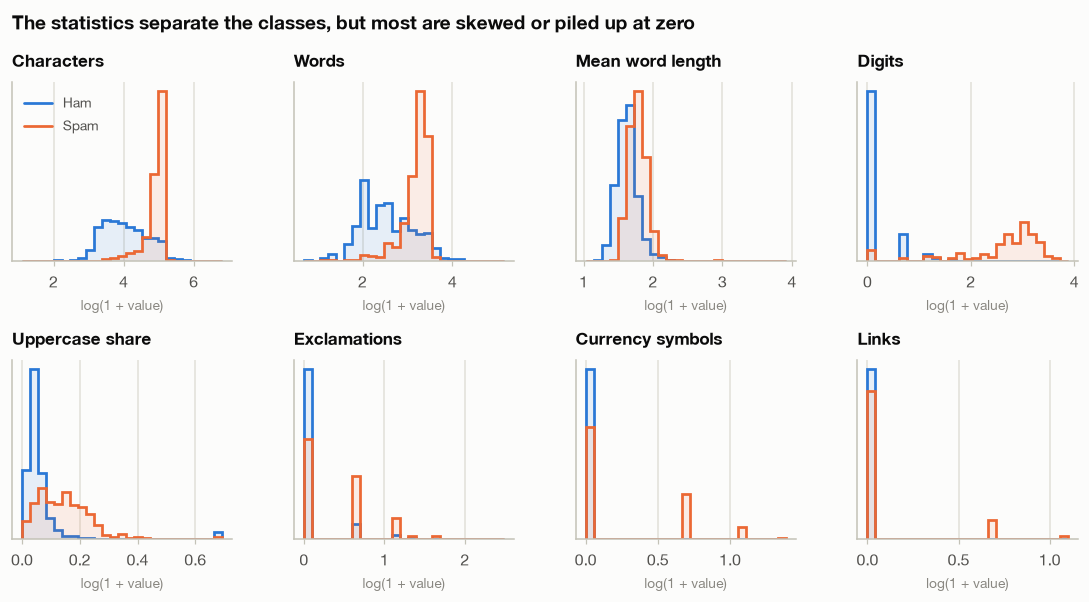

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(12.5, 5.4), gridspec_kw={"hspace": 0.55, "wspace": 0.28})
for ax, column in zip(axes.flat, NUMERIC):
    values = np.log1p(train[column])
    bins = np.histogram_bin_edges(values, bins=25)
    for label, colour in [("ham", HAM), ("spam", SPAM)]:
        share, _ = np.histogram(values[train["label"] == label], bins=bins)
        share = share / share.sum()
        ax.stairs(share, bins, color=colour, linewidth=1.8, label=label.capitalize())
        ax.stairs(share, bins, color=colour, alpha=0.10, fill=True)
    ax.set_title(column.replace("_", " ").capitalize(), fontsize=11)
    ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("log(1 + value)", fontsize=9, color=MUTED)
axes.flat[0].legend(loc="upper left", fontsize=9)
fig.suptitle("The statistics separate the classes, but most are skewed or piled up at zero",
             x=0.125, ha="left", fontsize=12.5, fontweight="bold", color=INK, y=1.0)
save(fig, "fig2_message_statistics.png")

In [40]:
# Most frequent words in each class (training set, English stop words removed)
vec_eda = CountVectorizer(token_pattern=r"(?u)\b\w+\b", stop_words=list(ENGLISH_STOP_WORDS))
counts_eda = vec_eda.fit_transform(train["clean_text"])
vocab_eda = vec_eda.get_feature_names_out()
top = {}
for label, flag in [("ham", 0), ("spam", 1)]:
    totals = np.asarray(counts_eda[y_train == flag].sum(axis=0)).ravel()
    order = np.argsort(-totals)[:12]
    top[f"{label} word"] = vocab_eda[order]
    top[f"{label} count"] = totals[order]
pd.DataFrame(top)

,ham word,ham count,spam word,spam count
0,u,743,phonetoken,493
1,s,375,numtoken,354
2,m,320,moneytoken,320
3,t,305,free,157
4,numtoken,247,2,133
5,2,241,u,116
6,just,230,txt,104
7,ok,212,ur,98
8,ll,193,urltoken,98
9,come,183,stop,92


## 3. Method

### 3.1 Naive Bayes in one equation

For a message $x$ and a class $y \in \{\text{ham}, \text{spam}\}$, Bayes' rule gives

$$P(y \mid x) = \frac{P(y)\,P(x \mid y)}{P(x)} \;\propto\; P(y)\,P(x \mid y).$$

The *naive* step assumes the features $x_1, \dots, x_d$ are independent once the class is known, so $P(x \mid y) = \prod_j P(x_j \mid y)$. Multiplying thousands of small probabilities underflows to zero, so everything is computed in logs:

$$\log P(y \mid x) = \log P(y) + \sum_j \log P(x_j \mid y) + \text{const}.$$

The variants differ only in the model for $P(x_j \mid y)$:

| Variant | Feature type | Likelihood $P(x \mid y)$ | Used here for |
|---|---|---|---|
| Multinomial | word **counts** $x_w$ | $\prod_w \theta_{yw}^{\,x_w}$ with $\theta_{yw} = \dfrac{N_{yw} + \alpha}{N_y + \alpha V}$ | message words |
| Bernoulli | word **presence** $b_w \in \{0,1\}$ | $\prod_w \theta_{yw}^{\,b_w}(1-\theta_{yw})^{1-b_w}$ | comparison |
| Gaussian | **continuous** values $x_j$ | $\prod_j \mathcal{N}(x_j;\ \mu_{yj}, \sigma^2_{yj})$ | numeric statistics |

$N_{yw}$ counts word $w$ in the training messages of class $y$, $N_y$ is that class's total word count, $V$ the vocabulary size and $\alpha$ a smoothing pseudo-count ($\alpha = 1$ is Laplace smoothing). Without smoothing, one word never seen in ham would make $P(\text{ham} \mid x) = 0$ for any message containing it, whatever else the message says.

### 3.2 Multinomial or Gaussian? Both, each where it fits

- **Words → multinomial.** A message is a bag of word tokens, and the multinomial model is exactly the story "each word is drawn from a class-specific word distribution". Word counts are discrete, non-negative and almost always zero: a message uses about 15 of the ~7,000 vocabulary words. That is the opposite of a bell curve.
- **Numeric statistics → Gaussian.** Length, digits, uppercase share and the rest are measurements on a continuous scale, so each gets a class-specific normal distribution. They are right-skewed (Figure 2 is on a log axis for this reason), so $\log(1 + x)$ is applied before fitting.
- **The wrong tool, on purpose.** Gaussian NB is also fitted to the raw word counts, to show what happens when the event model does not match the data.
- **Hybrid: both at once.** The naive assumption says words and statistics are independent given the class, so their log-likelihoods simply add:
  $\log P(y \mid x) = \log P(y) + \log P_{\text{multinomial}}(\text{words} \mid y) + \log P_{\text{Gaussian}}(\text{statistics} \mid y) + \text{const}.$
  Each sub-model's joint log-likelihood already contains the prior, so one copy is subtracted.
- **Reference model.** Logistic regression on the same word counts, the usual discriminative alternative, shows whether Naive Bayes gives up any accuracy for its simplicity.

### 3.3 Naive Bayes from scratch

To show that nothing is hidden inside scikit-learn, here is multinomial Naive Bayes in ten lines of NumPy. It is checked against `sklearn.naive_bayes.MultinomialNB` on the training data (the test set stays sealed).

In [41]:
TOKEN_PATTERN = r"(?u)\b\w+\b"  # keeps one-letter words such as "u" and "r" (SMS slang)


class ScratchMultinomialNB:
    # Multinomial Naive Bayes with Lidstone smoothing, written directly from the equations above.

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        counts = np.vstack([np.asarray(X[y == c].sum(axis=0)).ravel() for c in self.classes_])  # N_yw
        smoothed = counts + self.alpha
        self.feature_log_prob_ = np.log(smoothed) - np.log(smoothed.sum(axis=1, keepdims=True))  # log theta_yw
        self.class_log_prior_ = np.log([np.mean(y == c) for c in self.classes_])  # log P(y)
        return self

    def predict_log_proba(self, X):
        joint = X @ self.feature_log_prob_.T + self.class_log_prior_  # log P(y) + sum_w x_w log theta_yw
        return joint - logsumexp(joint, axis=1, keepdims=True)  # normalise in log space

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_log_proba(X), axis=1)]


vec = CountVectorizer(token_pattern=TOKEN_PATTERN).fit(X_train["clean_text"])
W_train = vec.transform(X_train["clean_text"])
ours, theirs = ScratchMultinomialNB(alpha=1.0).fit(W_train, y_train), MultinomialNB(alpha=1.0).fit(W_train, y_train)
gap = np.abs(ours.predict_log_proba(W_train) - theirs.predict_log_proba(W_train)).max()
same = (ours.predict(W_train) == theirs.predict(W_train)).mean()
print(f"Vocabulary: {W_train.shape[1]:,} words; {W_train.nnz / W_train.shape[0]:.1f} distinct words per message on average")
print(f"Largest gap in log-probabilities vs scikit-learn: {gap:.1e}")
print(f"Same prediction on {same:.0%} of the {W_train.shape[0]:,} training messages")

Vocabulary: 7,000 words; 14.4 distinct words per message on average
Largest gap in log-probabilities vs scikit-learn: 1.4e-14
Same prediction on 100% of the 4,127 training messages


In [42]:
class HybridNB(ClassifierMixin, BaseEstimator):
    # Multinomial NB on the words + Gaussian NB on log(1 + statistics), joined by adding log-likelihoods.

    def __init__(self, alpha=0.1, ngram_range=(1, 1), var_smoothing=1e-9):
        self.alpha = alpha
        self.ngram_range = ngram_range
        self.var_smoothing = var_smoothing

    def _parts(self, X):
        return self.vectorizer_.transform(X["clean_text"]), np.log1p(X[NUMERIC])

    def fit(self, X, y):
        self.vectorizer_ = CountVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=self.ngram_range)
        self.vectorizer_.fit(X["clean_text"])
        words, stats = self._parts(X)
        self.words_ = MultinomialNB(alpha=self.alpha).fit(words, y)
        self.stats_ = GaussianNB(var_smoothing=self.var_smoothing).fit(stats, y)
        self.classes_ = self.words_.classes_
        return self

    def joint_log_likelihood(self, X):
        words, stats = self._parts(X)
        return (self.words_.predict_joint_log_proba(words) + self.stats_.predict_joint_log_proba(stats)
                - self.words_.class_log_prior_)  # the prior is in both terms; keep one copy

    def predict_log_proba(self, X):
        joint = self.joint_log_likelihood(X)
        return joint - logsumexp(joint, axis=1, keepdims=True)

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]

## 4. Training and tuning

**Protocol.** Every model is tuned by a grid search with **5-fold stratified cross-validation on the training set**, scored by **F1 on the spam class**. F1 balances precision (flagged messages that really are spam) and recall (spam that gets caught), and unlike accuracy it cannot be gamed by predicting "ham" for everything. The model with the best cross-validated F1 among the Naive Bayes variants becomes the final filter. The test set is used once, in Section 5, to report results.

| Model | Input | Settings searched |
|---|---|---|
| Majority class | none | always predicts ham (baseline) |
| Multinomial NB | word counts | smoothing $\alpha$; unigrams or unigrams + bigrams |
| Bernoulli NB | word presence | $\alpha$; n-grams |
| Gaussian NB | word counts (2,000 most frequent words) | variance smoothing |
| Gaussian NB | 8 statistics, $\log(1+x)$ | variance smoothing |
| Hybrid NB | words + statistics | $\alpha$; n-grams; variance smoothing |
| Logistic regression | word counts | regularisation $C$; n-grams |

In [43]:
def text_column(frame):
    return frame["clean_text"]


def statistics_columns(frame):
    return frame[NUMERIC]


def to_dense(matrix):
    return matrix.toarray()


def word_counts(**options):
    return [("text", FunctionTransformer(text_column)),
            ("counts", CountVectorizer(token_pattern=TOKEN_PATTERN, **options))]


ALPHAS, NGRAMS = [0.01, 0.03, 0.1, 0.3, 1.0], [(1, 1), (1, 2)]
VAR_SMOOTHING = [1e-9, 1e-6, 1e-3, 1e-1]
MODELS = {
    "majority": ("Majority class (always ham)", DummyClassifier(strategy="prior"), {}),
    "mnb": ("Multinomial NB · word counts", Pipeline(word_counts() + [("nb", MultinomialNB())]),
            {"counts__ngram_range": NGRAMS, "nb__alpha": ALPHAS}),
    "bnb": ("Bernoulli NB · word presence", Pipeline(word_counts() + [("nb", BernoulliNB())]),
            {"counts__ngram_range": NGRAMS, "nb__alpha": ALPHAS}),
    "gnb_words": ("Gaussian NB · word counts",
                  Pipeline(word_counts(max_features=2000) + [("dense", FunctionTransformer(to_dense)), ("nb", GaussianNB())]),
                  {"nb__var_smoothing": VAR_SMOOTHING}),
    "gnb_stats": ("Gaussian NB · 8 message statistics",
                  Pipeline([("stats", FunctionTransformer(statistics_columns)), ("log", FunctionTransformer(np.log1p)),
                            ("nb", GaussianNB())]),
                  {"nb__var_smoothing": VAR_SMOOTHING}),
    "hybrid": ("Hybrid NB · words + statistics", HybridNB(),
               {"alpha": [0.03, 0.1, 0.3, 1.0], "ngram_range": NGRAMS, "var_smoothing": [1e-9, 1e-3]}),
    "logreg": ("Logistic regression · word counts", Pipeline(word_counts() + [("lr", LogisticRegression(solver="liblinear"))]),
               {"counts__ngram_range": NGRAMS, "lr__C": [0.1, 1.0, 10.0, 100.0]}),
}
NAMES = {key: spec[0] for key, spec in MODELS.items()}
NB_KEYS = ["mnb", "bnb", "gnb_words", "gnb_stats", "hybrid"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, cv_rows = {}, []
for key, (name, estimator, grid) in MODELS.items():
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv).fit(X_train, y_train)
    best = search.best_index_
    settings = ", ".join(f"{k.split('__')[-1]}={v}" for k, v in search.best_params_.items())
    cv_rows.append({"key": key, "model": name, "best settings": settings or "none",
                    "CV F1": search.cv_results_["mean_test_score"][best],
                    "CV F1 sd": search.cv_results_["std_test_score"][best]})
    fitted[key] = search.best_estimator_

cv_table = pd.DataFrame(cv_rows).set_index("key")
final_key = cv_table.loc[NB_KEYS, "CV F1"].idxmax()
print("Final filter (best cross-validated F1 among the Naive Bayes models):", NAMES[final_key])
cv_table

Final filter (best cross-validated F1 among the Naive Bayes models): Bernoulli NB · word presence


,model,best settings,CV F1,CV F1 sd
key,,,,
majority,Majority class (always ham),none,0.000,0.000
mnb,Multinomial NB · word counts,"ngram_range=(1, 1), alpha=0.1",0.955,0.006
bnb,Bernoulli NB · word presence,"ngram_range=(1, 1), alpha=0.1",0.967,0.003
gnb_words,Gaussian NB · word counts,var_smoothing=0.1,0.859,0.025
gnb_stats,Gaussian NB · 8 message statistics,var_smoothing=1e-09,0.886,0.024
hybrid,Hybrid NB · words + statistics,"alpha=0.1, ngram_range=(1, 2), var_smoothing=1e-09",0.963,0.003
logreg,Logistic regression · word counts,"ngram_range=(1, 1), C=100.0",0.951,0.005


**What this shows.** Bernoulli NB has the best cross-validated F1 (0.967 ± 0.003), just ahead of the hybrid (0.963) and multinomial NB (0.955), so it becomes the final filter. SMS messages are short (14 distinct words on average), so counts are nearly always 0 or 1 and a presence model loses almost nothing. It also scores the *absence* of typical spam words. Gaussian NB on word counts is the weakest word model (0.859), as the event-model mismatch predicts.

**Does the text normalisation help?** The same multinomial model and grid, trained once on raw lower-cased text and once on the normalised text:

In [44]:
check = {}
for label, texts in [("raw lower-cased text", train["text"].str.lower()), ("normalised text", train["clean_text"])]:
    search = GridSearchCV(Pipeline([("counts", CountVectorizer(token_pattern=TOKEN_PATTERN)), ("nb", MultinomialNB())]),
                          {"counts__ngram_range": NGRAMS, "nb__alpha": ALPHAS}, scoring="f1", cv=cv).fit(texts, y_train)
    unigrams = CountVectorizer(token_pattern=TOKEN_PATTERN).fit(texts)
    check[label] = {"CV F1": search.best_score_, "CV F1 sd": search.cv_results_["std_test_score"][search.best_index_],
                    "unigram vocabulary": len(unigrams.vocabulary_)}
pd.DataFrame(check).T

,CV F1,CV F1 sd,unigram vocabulary
raw lower-cased text,0.956,0.003,7614.0
normalised text,0.955,0.006,7000.0


Normalisation leaves F1 unchanged (0.955 vs 0.956, well inside one standard deviation) and shrinks the vocabulary by 8%. It stays for robustness to unseen phone numbers and to neutralise the placeholders.

## 5. Results

### 5.1 Held-out test set

Each tuned model now classifies the 1,032 test messages it has never seen. The 95% interval for F1 comes from 1,000 bootstrap resamples of the test set. "Ham flagged" (false positives) are legitimate messages a user would lose; "spam missed" (false negatives) reach the inbox.

In [45]:
def spam_score(model, X):
    # log P(spam | x) - log P(ham | x). Unlike probabilities, it does not round to exactly 0 or 1.
    log_p = model.predict_log_proba(X)
    return np.clip(log_p[:, 1] - log_p[:, 0], -1e4, 1e4)


rng = np.random.default_rng(SEED)
resamples = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
scores, rows = {}, []
for key, model in fitted.items():
    score = scores[key] = spam_score(model, X_test)
    pred = (score > 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    f1_boot = [f1_score(y_test[i], pred[i], zero_division=0) for i in resamples]
    rows.append({"key": key, "model": NAMES[key],
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "F1 95% CI": f"{np.percentile(f1_boot, 2.5):.3f}-{np.percentile(f1_boot, 97.5):.3f}",
                 "ROC AUC": roc_auc_score(y_test, score),
                 "PR AUC": average_precision_score(y_test, score),
                 "ham flagged": int(fp), "spam missed": int(fn)})
test_table = pd.DataFrame(rows).set_index("key")
test_table

,model,accuracy,precision,recall,F1,F1 95% CI,ROC AUC,PR AUC,ham flagged,spam missed
key,,,,,,,,,,
majority,Majority class (always ham),0.876,0.000,0.000,0.000,0.000-0.000,0.500,0.124,0,128
mnb,Multinomial NB · word counts,0.984,0.975,0.898,0.935,0.900-0.964,0.955,0.932,3,13
bnb,Bernoulli NB · word presence,0.984,1.000,0.875,0.933,0.896-0.964,0.982,0.962,0,16
gnb_words,Gaussian NB · word counts,0.956,0.956,0.680,0.795,0.731-0.852,0.951,0.869,4,41
gnb_stats,Gaussian NB · 8 message statistics,0.953,0.794,0.844,0.818,0.769-0.865,0.967,0.877,28,20
hybrid,Hybrid NB · words + statistics,0.980,0.935,0.898,0.916,0.877-0.949,0.977,0.939,8,13
logreg,Logistic regression · word counts,0.980,0.973,0.859,0.913,0.870-0.949,0.962,0.926,3,18


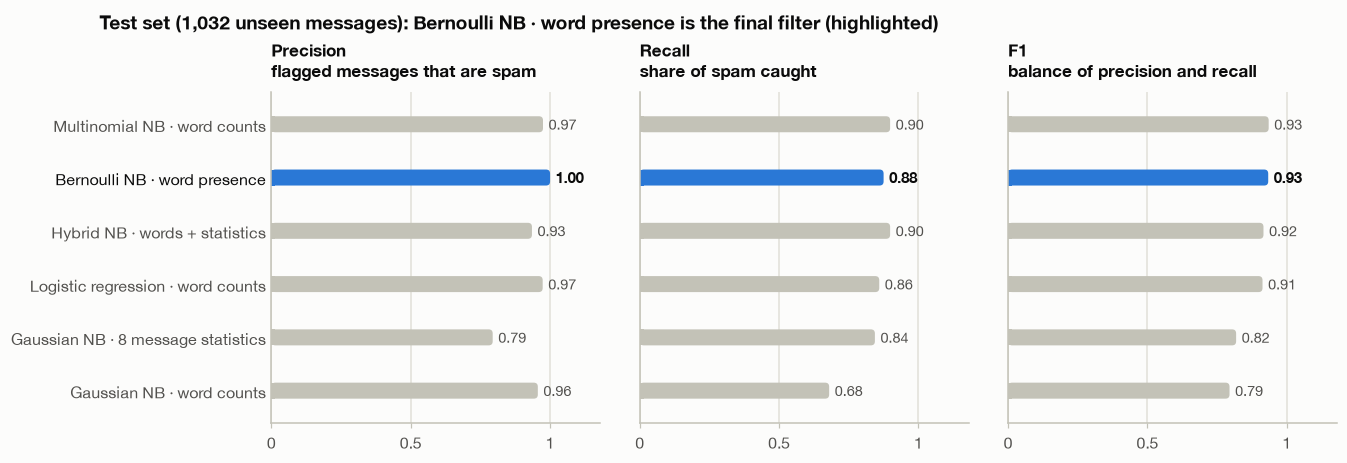

In [46]:
order = test_table.drop(index="majority").sort_values("F1").index  # weakest at the bottom
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, metric, title in zip(axes, ["precision", "recall", "F1"],
                             ["Precision\nflagged messages that are spam", "Recall\nshare of spam caught",
                              "F1\nbalance of precision and recall"]):
    ax.set_xlim(0, 1.18); ax.set_ylim(-0.6, len(order) - 0.4)
    unit = pixel_size(ax)
    for row, key in enumerate(order):
        value = test_table.loc[key, metric]
        hbar(ax, row, 0, value, MODEL_COLOUR.get(final_key, HAM) if key == final_key else GREY, unit)
        ax.text(value + 0.02, row, f"{value:.2f}", va="center", fontsize=9.5,
                color=INK if key == final_key else INK_2, fontweight="bold" if key == final_key else "normal")
    ax.set_title(title, fontsize=11); ax.grid(axis="y", visible=False)
    ax.set_xticks([0, 0.5, 1.0], ["0", "0.5", "1"])
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(order)), [NAMES[k] for k in order])
for label in axes[0].get_yticklabels():
    label.set_color(INK if label.get_text() == NAMES[final_key] else INK_2)
fig.suptitle(f"Test set ({len(y_test):,} unseen messages): {NAMES[final_key]} is the final filter (highlighted)",
             x=0.0, ha="left", fontsize=12.5, fontweight="bold", color=INK, y=1.07)
save(fig, "fig3_model_comparison.png")

**What this shows.** The final Bernoulli filter, chosen by cross-validation before the test set was opened, flags **none** of the 904 legitimate test messages (precision 1.00) and catches 112 of 128 spam (recall 0.875, F1 0.933). Multinomial NB is statistically tied (F1 0.935; the bootstrap intervals overlap almost completely) but flags 3 ham. Both beat the logistic-regression reference (0.913). The majority baseline shows why accuracy misleads: 87.6% accuracy while catching no spam at all.

### 5.2 Confusion matrices

The five Naive Bayes models side by side: the same Bayes rule with different event models, the final filter first. Rows are the true class and columns the prediction; shading shows the share of each true class.

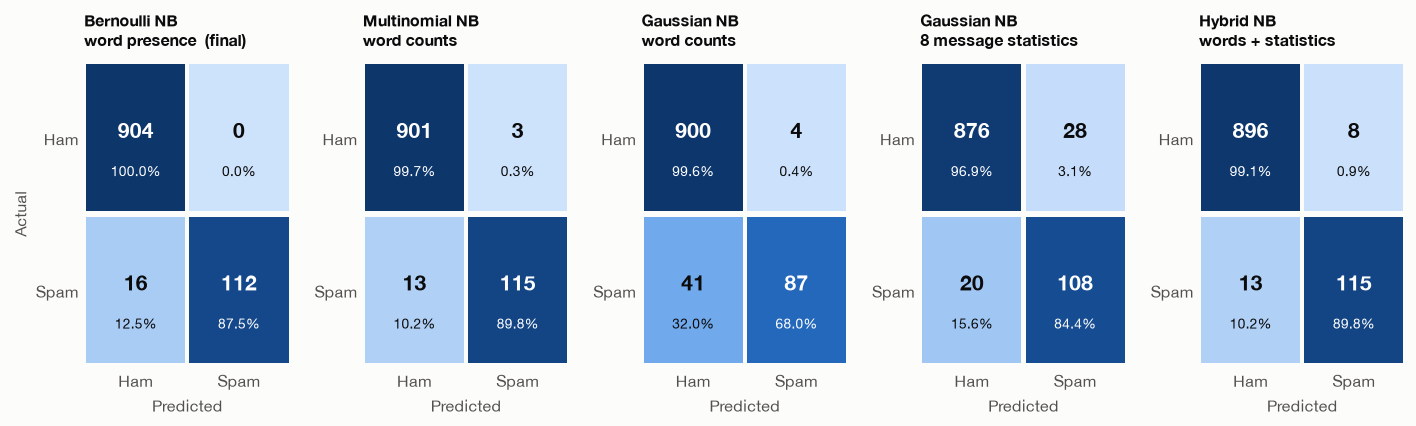

In [47]:
panel_keys = [final_key] + [k for k in ["mnb", "bnb", "gnb_words", "gnb_stats", "hybrid"] if k != final_key]
fig, axes = plt.subplots(1, len(panel_keys), figsize=(15.5, 3.6), gridspec_kw={"wspace": 0.35})
for ax, key in zip(axes, panel_keys):
    cm = confusion_matrix(y_test, (scores[key] > 0).astype(int), labels=[0, 1])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.set_xlim(0, 2); ax.set_ylim(2, 0)
    for i in range(2):
        for j in range(2):
            colour = BLUES(share[i, j])
            ax.add_patch(Rectangle((j + 0.02, i + 0.02), 0.96, 0.96, facecolor=colour, linewidth=0))
            luminance = np.dot(to_rgb(colour), [0.2126, 0.7152, 0.0722])
            ink = "white" if luminance < 0.55 else INK
            ax.text(j + 0.5, i + 0.45, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14, fontweight="bold", color=ink)
            ax.text(j + 0.5, i + 0.72, f"{share[i, j]:.1%}", ha="center", va="center", fontsize=9, color=ink)
    ax.set_xticks([0.5, 1.5], ["Ham", "Spam"]); ax.set_yticks([0.5, 1.5], ["Ham", "Spam"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if key == panel_keys[0] else "")
    ax.tick_params(length=0); ax.grid(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_title(NAMES[key].replace(" · ", "\n") + ("  (final)" if key == final_key else ""), fontsize=10.5)
save(fig, "fig4_confusion_matrices.png")

Each mismatch between event model and data fails in its own way. Gaussian NB on word counts rarely flags ham (4) but misses a third of the spam (41 of 128). Gaussian NB on the statistics catches more spam but flags 28 ham, because long, number-heavy ham looks like spam on length and digits alone. The hybrid inherits some of those false alarms (8, vs 3 for multinomial NB alone).

### 5.3 ROC and precision-recall curves

The curves rank test messages by spam score and sweep the decision threshold, for the final filter, multinomial NB, Gaussian NB on the statistics and the logistic-regression reference. Precision-recall is the more telling view here, because only 12% of messages are spam.

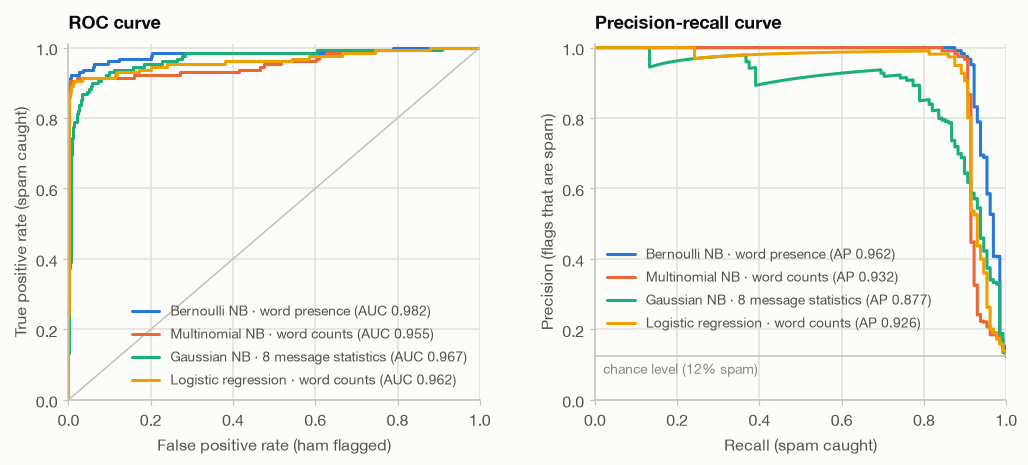

,spam ranked below the median ham,lowest P(spam) given to a spam message
Bernoulli NB · word presence,2,4.140e-14
Multinomial NB · word counts,6,6.447e-18
Gaussian NB · 8 message statistics,2,3.655e-15
Logistic regression · word counts,5,5.589e-07


In [48]:
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.28})
for key in ["bnb", "mnb", "gnb_stats", "logreg"]:
    fpr, tpr, _ = roc_curve(y_test, scores[key])
    roc_ax.plot(fpr, tpr, color=MODEL_COLOUR[key], label=f"{NAMES[key]} (AUC {test_table.loc[key, 'ROC AUC']:.3f})")
    precision, recall, _ = precision_recall_curve(y_test, scores[key])
    pr_ax.plot(recall, precision, color=MODEL_COLOUR[key], label=f"{NAMES[key]} (AP {test_table.loc[key, 'PR AUC']:.3f})")
roc_ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
roc_ax.set(xlabel="False positive rate (ham flagged)", ylabel="True positive rate (spam caught)",
           xlim=(0, 1), ylim=(0, 1.01))
roc_ax.set_title("ROC curve")
roc_ax.legend(loc="lower right", fontsize=9)
pr_ax.axhline(y_test.mean(), color=AXIS, linewidth=1)
pr_ax.text(0.02, y_test.mean() - 0.05, f"chance level ({y_test.mean():.0%} spam)", color=MUTED, fontsize=9)
pr_ax.set(xlabel="Recall (spam caught)", ylabel="Precision (flags that are spam)", xlim=(0, 1), ylim=(0, 1.01))
pr_ax.set_title("Precision-recall curve")
pr_ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.16), fontsize=9)
save(fig, "fig5_roc_pr_curves.png")
ranking = pd.DataFrame({
    "spam ranked below the median ham": {NAMES[k]: int((scores[k][y_test == 1] < np.median(scores[k][y_test == 0])).sum())
                                         for k in ["bnb", "mnb", "gnb_stats", "logreg"]},
    "lowest P(spam) given to a spam message": {NAMES[k]: float(expit(scores[k][y_test == 1].min()))
                                               for k in ["bnb", "mnb", "gnb_stats", "logreg"]},
})
ranking

Bernoulli NB also ranks messages best (ROC AUC 0.982, average precision 0.962). Multinomial NB has the lowest ROC AUC of the four (0.955) despite its high F1: it ranks 6 spam messages below the median ham message, one of them at P(spam) ≈ 6 × 10⁻¹⁸, which flattens the right end of its curve. That is the over-confidence measured in 5.8.

### 5.4 What gives spam away

Naive Bayes is fully transparent: each word's evidence is the ratio $\theta_{\text{spam},w} / \theta_{\text{ham},w}$, how many times more often the word occurs in spam than in ham. The chart uses the multinomial model's word probabilities (unigrams, training set, words seen at least 20 times so rare words do not dominate); the cell also checks that the final Bernoulli model ranks those words the same way.

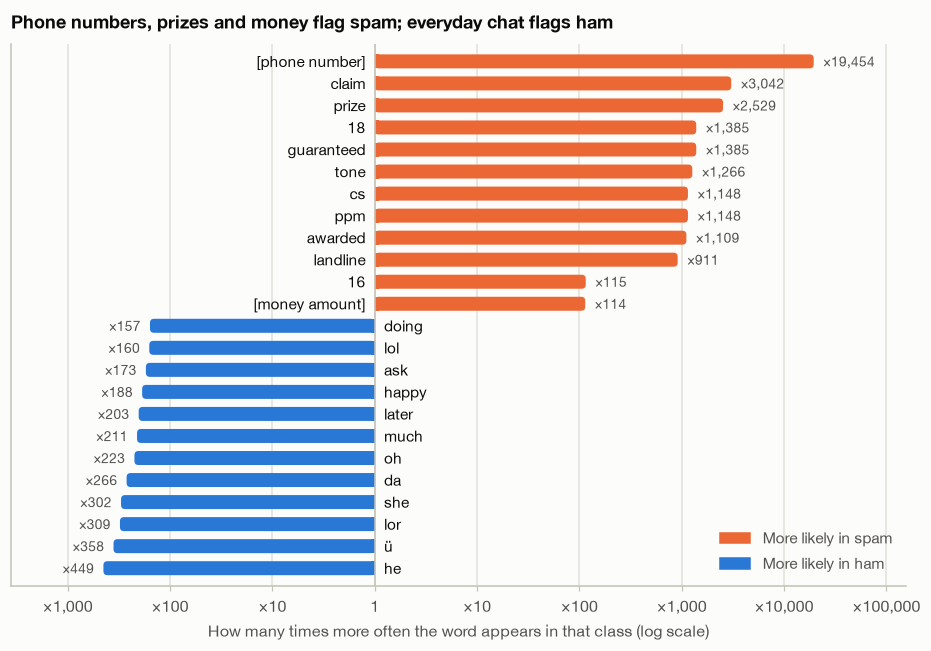

Rank correlation between multinomial and Bernoulli word evidence (common words): 0.998


,direction,word,ham count,spam count,log2 ratio
4540,spam,[phone number],0,493,14.248
1269,spam,claim,0,77,11.571
4764,spam,prize,0,64,11.304
29,spam,18,0,35,10.435
2659,spam,guaranteed,0,35,10.435
6245,spam,tone,0,32,10.307
1528,spam,cs,0,29,10.165
4687,spam,ppm,0,29,10.165
644,spam,awarded,0,28,10.115
3392,spam,landline,0,23,9.832


In [49]:
best_alpha = fitted["mnb"].named_steps["nb"].alpha
vec_uni = CountVectorizer(token_pattern=TOKEN_PATTERN).fit(X_train["clean_text"])
W_uni = vec_uni.transform(X_train["clean_text"])
nb_uni = MultinomialNB(alpha=best_alpha).fit(W_uni, y_train)
DISPLAY = {"phonetoken": "[phone number]", "numtoken": "[long number]", "moneytoken": "[money amount]",
           "urltoken": "[web link]", "emailtoken": "[e-mail address]"}
words_table = pd.DataFrame({
    "word": [DISPLAY.get(w, w) for w in vec_uni.get_feature_names_out()],
    "ham count": np.asarray(W_uni[y_train == 0].sum(axis=0)).ravel(),
    "spam count": np.asarray(W_uni[y_train == 1].sum(axis=0)).ravel(),
    "log2 ratio": (nb_uni.feature_log_prob_[1] - nb_uni.feature_log_prob_[0]) / np.log(2),
})
common = words_table[words_table["ham count"] + words_table["spam count"] >= 20]
top_spam = common.nlargest(12, "log2 ratio")
top_ham = common.nsmallest(12, "log2 ratio")

fig, ax = plt.subplots(figsize=(10.5, 6.4))
both = pd.concat([top_ham, top_spam.iloc[::-1]])  # rows bottom-up: strongest ham first, strongest spam last
left_lim, right_lim = -both["log2 ratio"].min() + 3, both["log2 ratio"].max() + 3
lim = max(left_lim, right_lim)
ax.set_xlim(-left_lim, right_lim); ax.set_ylim(-0.8, len(both) - 0.2)
unit = pixel_size(ax)
for row, (_, r) in enumerate(both.iterrows()):
    value, spammy = r["log2 ratio"], r["log2 ratio"] > 0
    hbar(ax, row, 0, value, SPAM if spammy else HAM, unit, thickness_px=14)
    times = 2 ** abs(value)
    ax.text(-0.3 if spammy else 0.3, row, r["word"], va="center", ha="right" if spammy else "left",
            fontsize=10, color=INK)
    ax.text(value + (0.3 if spammy else -0.3), row, f"×{times:,.0f}" if times >= 10 else f"×{times:.1f}",
            va="center", ha="left" if spammy else "right", fontsize=9, color=INK_2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks([]); ax.grid(axis="y", visible=False)
left_powers = [k for k in range(1, 6) if k * np.log2(10) < left_lim - 0.5]
right_powers = [k for k in range(1, 6) if k * np.log2(10) < right_lim - 0.5]
ticks = [-k * np.log2(10) for k in left_powers[::-1]] + [0] + [k * np.log2(10) for k in right_powers]
ax.set_xticks(ticks, [f"×{10 ** k:,}" for k in left_powers[::-1]] + ["1"] + [f"×{10 ** k:,}" for k in right_powers])
ax.set_xlabel("How many times more often the word appears in that class (log scale)")
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=SPAM), Rectangle((0, 0), 1, 1, color=HAM)],
          labels=["More likely in spam", "More likely in ham"], loc="lower right")
ax.set_title("Phone numbers, prizes and money flag spam; everyday chat flags ham")
save(fig, "fig6_top_words.png")
bnb_uni = BernoulliNB(alpha=fitted["bnb"].named_steps["nb"].alpha).fit(W_uni, y_train)
presence = (bnb_uni.feature_log_prob_[1] - bnb_uni.feature_log_prob_[0])[common.index]
rho = spearmanr(common["log2 ratio"], presence).statistic
print(f"Rank correlation between multinomial and Bernoulli word evidence (common words): {rho:.3f}")
pd.concat([top_spam.assign(direction="spam"), top_ham.assign(direction="ham")])[["direction", "word", "ham count", "spam count", "log2 ratio"]]

In [50]:
# Evidence from the numeric statistics: the Gaussian model's class means on the log(1 + x) scale
gnb = fitted["gnb_stats"].named_steps["nb"]
pd.DataFrame({"ham mean": np.expm1(gnb.theta_[0]), "spam mean": np.expm1(gnb.theta_[1])}, index=NUMERIC).round(2)

,ham mean,spam mean
characters,55.67,132.40
words,11.39,22.66
mean_word_length,4.05,4.91
digits,0.20,12.09
uppercase_share,0.07,0.16
exclamations,0.10,0.51
currency_symbols,0.00,0.31
links,0.00,0.11


**What this shows.** Spam evidence comes from contact and reward words ([phone number], claim, prize, guaranteed, awarded), premium-rate jargon (ppm = pence per minute, cs = customer service, tone = ringtone, landline) and age gates (18, 16). Ham evidence is everyday chat (he, she, lol, later, happy) and Singlish particles (lor, da, ü for "you"), a reminder that most ham here comes from Singaporean students. Words never seen in ham get ratios set by the smoothing $\alpha$, so "×19,454" means "very large", not an exact multiplier. On the statistics side, a typical spam has 132 characters and 12 digits; a typical ham has 56 characters and almost none.

### 5.5 Choosing the decision threshold

The default rule flags a message when $P(\text{spam} \mid x) > 0.5$. But the two errors do not cost the same: losing a real message (a false positive) is worse than seeing one more spam. Assume a false positive costs **10 times** a missed spam. The threshold is chosen to minimise that cost on **out-of-fold predictions for the training set**, never on the test set, and then applied once to the test set.

In [51]:
final = fitted[final_key]
oof_log_p = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_log_proba")
oof_score = np.clip(oof_log_p[:, 1] - oof_log_p[:, 0], -1e4, 1e4)

COST_FP, COST_FN = 10, 1
candidates = np.unique(np.clip(oof_score, -60, 60))
cost = [COST_FP * np.sum((oof_score > t) & (y_train == 0)) + COST_FN * np.sum((oof_score <= t) & (y_train == 1))
        for t in candidates]
best_t = float(candidates[int(np.argmin(cost))])
print(f"Cost-minimising cut-off: spam score > {best_t:.2f} (log-odds), i.e. P(spam) > {expit(best_t):.4f}")


def outcome(y, score, cutoff):
    pred = (score > cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"ham flagged": fp, "spam missed": fn, "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn),
            "cost (10×FP + FN)": COST_FP * fp + COST_FN * fn}


rules = {"default (P > 0.5)": 0.0, f"cost-based (P > {expit(best_t):.3f})": best_t}
print("Out-of-fold predictions on the training set (where the threshold was chosen):")
display(pd.DataFrame({name: outcome(y_train, oof_score, t) for name, t in rules.items()}).T)
print("Test set (threshold applied once):")
threshold_table = pd.DataFrame({name: outcome(y_test, scores[final_key], t) for name, t in rules.items()}).T
threshold_table

Cost-minimising cut-off: spam score > 4.88 (log-odds), i.e. P(spam) > 0.9925
Out-of-fold predictions on the training set (where the threshold was chosen):


,ham flagged,spam missed,precision,recall,cost (10×FP + FN)
default (P > 0.5),5.0,28.0,0.990,0.945,78.0
cost-based (P > 0.992),3.0,40.0,0.994,0.922,70.0


Test set (threshold applied once):


,ham flagged,spam missed,precision,recall,cost (10×FP + FN)
default (P > 0.5),0.0,16.0,1.0,0.875,16.0
cost-based (P > 0.992),0.0,19.0,1.0,0.852,19.0


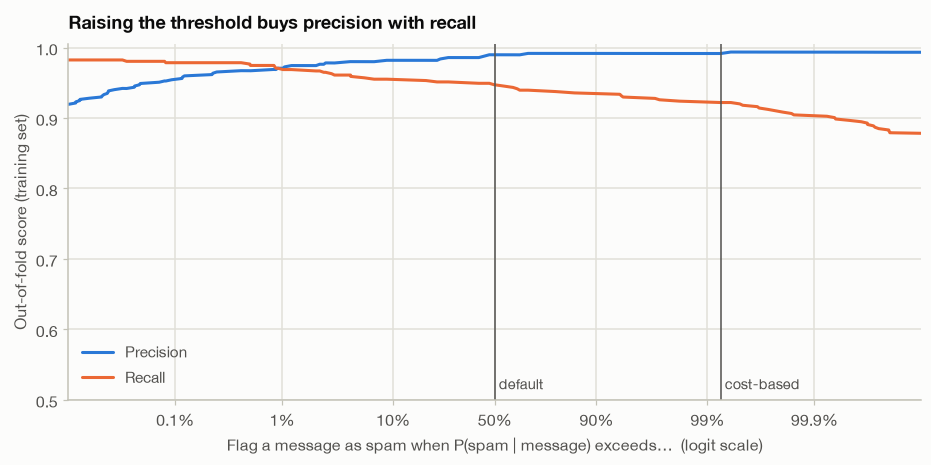

In [52]:
precision, recall, cut = precision_recall_curve(y_train, oof_score)
p_cut = expit(np.clip(cut, -30, 30))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(p_cut, precision[:-1], color=HAM, label="Precision")
ax.plot(p_cut, recall[:-1], color=SPAM, label="Recall")
ax.set_xscale("logit")
ax.set_xlim(1e-4, 1 - 1e-4); ax.set_ylim(0.5, 1.005)
ticks = [1e-3, 1e-2, 0.1, 0.5, 0.9, 0.99, 0.999]
ax.set_xticks(ticks, ["0.1%", "1%", "10%", "50%", "90%", "99%", "99.9%"]); ax.minorticks_off()
for x, label in [(0.5, "default"), (expit(best_t), "cost-based")]:
    ax.axvline(x, color=INK_2, linewidth=1)
    ax.text(x, 0.515, f" {label}", color=INK_2, fontsize=9.5)
ax.set_xlabel("Flag a message as spam when P(spam | message) exceeds…  (logit scale)")
ax.set_ylabel("Out-of-fold score (training set)")
ax.legend(loc="lower left")
ax.set_title("Raising the threshold buys precision with recall")
save(fig, "fig7_threshold.png")

On the training folds, the 10:1 cost moves the cut-off from 0.5 to P(spam) > 0.993; there it cut false alarms from 5 to 3 at the price of 12 more missed spam (cost 78 → 70). On the test set it removes no false positives (there were none to remove) and lets 3 more spam through (cost 19 vs 16). Bernoulli NB is already conservative at 0.5, so the default threshold stays.

### 5.6 Error analysis

The final filter's mistakes on the test set (default threshold), with its estimated probability of spam.

In [53]:
review = test[["label", "text"]].assign(p_spam=expit(scores[final_key]), flagged=scores[final_key] > 0)
false_positives = review[(review["label"] == "ham") & review["flagged"]].sort_values("p_spam", ascending=False)
false_negatives = review[(review["label"] == "spam") & ~review["flagged"]].sort_values("p_spam")
print(f"Ham flagged as spam: {len(false_positives)}")
false_positives[["text", "p_spam"]]

Ham flagged as spam: 0


,text,p_spam


In [54]:
tokens = r"phonetoken|moneytoken|urltoken"
with_token = test.loc[false_negatives.index, "clean_text"].str.contains(tokens).sum()
print(f"Spam that got through: {len(false_negatives)} "
      f"({with_token} contain a phone number, money amount or link; {len(false_negatives) - with_token} contain none)")
false_negatives[["text", "p_spam"]]

Spam that got through: 16 (4 contain a phone number, money amount or link; 12 contain none)


,text,p_spam
2816,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving...",4.140e-14
2642,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to s...,2.561e-12
848,Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need you...,3.027e-08
737,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",3.395e-08
3225,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't f...,2.053e-07
4216,Money i have won wining number 946 wot do i do next,3.954e-07
3884,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day,...",1.797e-06
2299,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. ...,2.186e-06
3630,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50",6.397e-06
3120,RCT' THNQ Adrian for U text. Rgds Vatian,1.161e-05


**What this shows.** No legitimate message was flagged. The 16 missed spam messages read like chat: jokes and trivia from subscription services, dating-line come-ons, a football score. Only 4 contain a phone number, money amount or link. Word-level evidence cannot separate them from ham; that would need sender information or a model of the call to action.

### 5.7 Learning curve: how much data does each model need?

Generative models such as Naive Bayes often reach their best accuracy with fewer examples than discriminative ones (Ng & Jordan, 2002). The curve trains on growing slices of the training folds and scores the held-out fold.

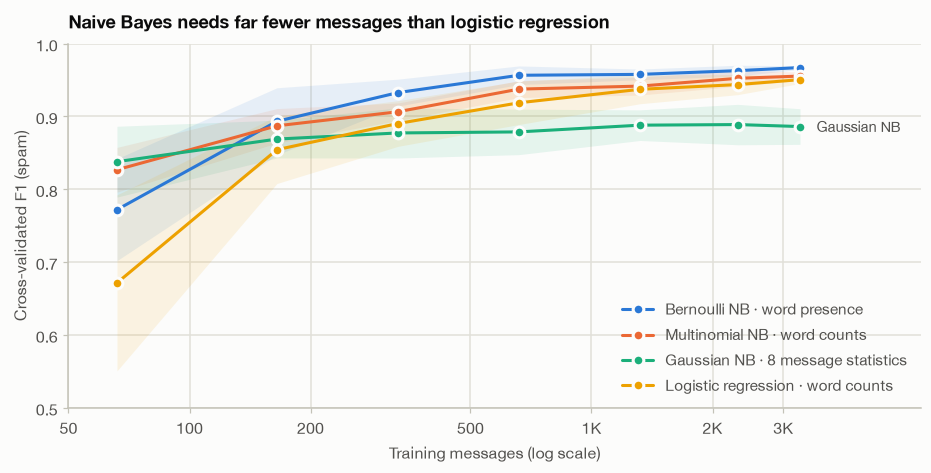

,Bernoulli NB · word presence,Multinomial NB · word counts,Gaussian NB · 8 message statistics,Logistic regression · word counts
messages,,,,
66,0.772,0.827,0.838,0.671
165,0.893,0.887,0.869,0.854
330,0.933,0.906,0.877,0.890
660,0.957,0.938,0.879,0.919
1320,0.958,0.942,0.888,0.937
2310,0.963,0.952,0.889,0.944
3301,0.967,0.955,0.886,0.951


In [55]:
fractions = np.array([0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0])
curves = {}
for key in ["bnb", "mnb", "gnb_stats", "logreg"]:
    sizes, _, valid = learning_curve(fitted[key], X_train, y_train, train_sizes=fractions, cv=cv,
                                     scoring="f1", shuffle=True, random_state=SEED)
    curves[key] = pd.DataFrame({"messages": sizes, "mean F1": valid.mean(axis=1), "sd": valid.std(axis=1)})

fig, ax = plt.subplots(figsize=(10, 4.3))
for key, curve in curves.items():
    ax.fill_between(curve["messages"], curve["mean F1"] - curve["sd"], curve["mean F1"] + curve["sd"],
                    color=MODEL_COLOUR[key], alpha=0.10, linewidth=0)
    ax.plot(curve["messages"], curve["mean F1"], color=MODEL_COLOUR[key], marker="o", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2, label=NAMES[key])
end = curves["gnb_stats"].iloc[-1]
ax.text(end["messages"] * 1.1, end["mean F1"], "Gaussian NB", va="center", fontsize=9.5, color=INK_2)
ax.set_xscale("log")
ax.set_xlim(curves["mnb"]["messages"].iloc[0] * 0.8, curves["mnb"]["messages"].iloc[-1] * 2.0)
ax.set_ylim(0.5, 1)
ax.set_xticks([50, 100, 200, 500, 1000, 2000, 3000], ["50", "100", "200", "500", "1K", "2K", "3K"]); ax.minorticks_off()
ax.set_xlabel("Training messages (log scale)"); ax.set_ylabel("Cross-validated F1 (spam)")
ax.legend(loc="lower right")
ax.set_title("Naive Bayes needs far fewer messages than logistic regression")
save(fig, "fig8_learning_curve.png")
pd.concat({NAMES[k]: c.set_index("messages")["mean F1"] for k, c in curves.items()}, axis=1).round(3)

With 66 training messages (about 8 spam), the three Naive Bayes models already reach F1 of 0.77–0.84, while logistic regression manages 0.67. Logistic regression closes most of the gap by about 1,000 messages but never overtakes the Naive Bayes word models: the classic generative-versus-discriminative pattern (Ng & Jordan, 2002). Gaussian NB on the statistics plateaus near 0.89, because eight numbers per message cannot carry as much information as the words.

### 5.8 Checking the assumptions

Naive Bayes rests on two assumptions that real messages break. The checks below measure by how much.

In [56]:
stats_train = X_train[NUMERIC]
gaussian_check = pd.DataFrame({"skewness (raw)": stats_train.apply(skew),
                               "skewness after log(1+x)": np.log1p(stats_train).apply(skew)})
print("1) Gaussian assumption: skewness of each statistic (0 for a normal distribution)")
display(gaussian_check)

corr = np.log1p(stats_train[y_train == 0]).corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("2) Independence assumption: most correlated statistics within ham")
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(4).to_frame("correlation"))

extreme = {NAMES[k]: float(np.mean(np.abs(scores[k]) > np.log(999))) for k in ["bnb", "mnb", "hybrid", "logreg"]}
print("3) Over-confidence: share of test messages scored with more than 99.9% certainty")
display(pd.Series(extreme, name="share of test messages").to_frame())

1) Gaussian assumption: skewness of each statistic (0 for a normal distribution)


,skewness (raw),skewness after log(1+x)
characters,2.378,-0.034
words,2.462,0.024
mean_word_length,14.677,1.408
digits,3.151,1.997
uppercase_share,5.131,4.455
exclamations,4.900,2.466
currency_symbols,5.507,4.778
links,8.688,7.856


2) Independence assumption: most correlated statistics within ham


correlation
characters words               0.972
words      digits              0.264
characters digits              0.246
           exclamations        0.228

3) Over-confidence: share of test messages scored with more than 99.9% certainty


,share of test messages
Bernoulli NB · word presence,0.990
Multinomial NB · word counts,0.892
Hybrid NB · words + statistics,0.997
Logistic regression · word counts,0.920


1. $\log(1+x)$ makes length almost perfectly symmetric (skewness 2.4 → 0.0) but cannot fix zero-inflated counts: links stay at 7.9, because most messages have none. A "bell curve" for those features is really a spike plus a tail, which is why Gaussian NB on the statistics flags ham.
2. Characters and words correlate at 0.97 within ham, so Gaussian NB counts message length twice. This is the independence assumption failing in plain sight, and it is why the hybrid flags more ham than the words alone.
3. Naive Bayes is over-confident: most of its test scores claim more than 99.9% certainty, far beyond what a 98% accurate model can justify. Its scores rank messages well, but they need calibration before they are used as probabilities.

### 5.9 Why the placeholder fix mattered

What if the `<#>` placeholder had been left as its own word? Refit the unigram model with it kept as a separate token and measure its evidence.

In [57]:
leaky_text = data["text"].str.replace("<#>", " anonnumber ", regex=False).map(normalise)
vec_leak = CountVectorizer(token_pattern=TOKEN_PATTERN).fit(leaky_text.loc[train.index])
W_leak = vec_leak.transform(leaky_text.loc[train.index])
nb_leak = MultinomialNB(alpha=best_alpha).fit(W_leak, y_train)
ratio = (nb_leak.feature_log_prob_[1] - nb_leak.feature_log_prob_[0]) / np.log(2)
j = vec_leak.vocabulary_["anonnumber"]
counts_leak = np.asarray(W_leak.sum(axis=0)).ravel()
rank = int((ratio[counts_leak >= 20] < ratio[j]).sum()) + 1
print(f"'<#>' appears {int(W_leak[y_train == 0, j].sum())} times in training ham and "
      f"{int(W_leak[y_train == 1, j].sum())} times in training spam.")
print(f"Each occurrence would make a message {2 ** -ratio[j]:.0f}× more likely to be ham; "
      f"it would rank #{rank} of {(counts_leak >= 20).sum()} common words as ham evidence.")

'<#>' appears 188 times in training ham and 0 times in training spam.
Each occurrence would make a message 477× more likely to be ham; it would rank #1 of 469 common words as ham evidence.


Left in place, `<#>` would have been the single strongest ham word in the vocabulary. That rule comes from how one corpus was anonymised, not from how people write, and it would silently fail on a real phone. Mapping the placeholder to the same token as real numbers removes the shortcut.

In [58]:
# Save the numbers used by the report and the slides
summary = {
    "raw_messages": int(len(raw)), "raw_spam": int((raw["label"] == "spam").sum()),
    "raw_exact_duplicates": int(raw.duplicated().sum()), "duplicates_removed": int(duplicate.sum()),
    "clean_messages": int(len(sms)), "clean_spam": int(sms["spam"].sum()), "spam_share": float(sms["spam"].mean()),
    "train_messages": int(len(train)), "test_messages": int(len(test)), "test_spam": int(y_test.sum()),
    "vocabulary": int(W_train.shape[1]), "scratch_vs_sklearn_max_gap": float(gap),
    "final_model": NAMES[final_key], "final_key": final_key,
    "cost_threshold_log_odds": best_t, "cost_threshold_probability": float(expit(best_t)),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
cv_table.to_csv(RESULTS_DIR / "cv_results.csv")
test_table.to_csv(RESULTS_DIR / "test_results.csv")
threshold_table.to_csv(RESULTS_DIR / "threshold_results.csv")
pd.concat([top_spam.assign(direction="spam"), top_ham.assign(direction="ham")]).to_csv(RESULTS_DIR / "top_words.csv", index=False)
pd.concat(curves, names=["model", "step"]).to_csv(RESULTS_DIR / "learning_curve.csv")
false_positives.to_csv(RESULTS_DIR / "false_positives.csv", index=False)
false_negatives.to_csv(RESULTS_DIR / "false_negatives.csv", index=False)

# Chart data for the slides: message length by class (training set) and test confusion counts per model
edges = list(range(0, 201, 20)) + [10_000]
bins = pd.cut(train["characters"], edges, right=False,
              labels=[f"{a}-{b - 1}" for a, b in zip(edges[:-2], edges[1:-1])] + ["200+"])
pd.crosstab(bins, train["label"], normalize="columns").to_csv(RESULTS_DIR / "length_histogram.csv")
pd.DataFrame({key: dict(zip(["ham kept", "ham flagged", "spam missed", "spam caught"],
                            confusion_matrix(y_test, (scores[key] > 0).astype(int), labels=[0, 1]).ravel().tolist()))
              for key in fitted}).T.to_csv(RESULTS_DIR / "confusion_counts.csv")
summary

{'raw_messages': 5574,
 'raw_spam': 747,
 'raw_exact_duplicates': 403,
 'duplicates_removed': 415,
 'clean_messages': 5159,
 'clean_spam': 641,
 'spam_share': 0.12424888544291529,
 'train_messages': 4127,
 'test_messages': 1032,
 'test_spam': 128,
 'vocabulary': 7000,
 'scratch_vs_sklearn_max_gap': 1.4210854715202004e-14,
 'final_model': 'Bernoulli NB · word presence',
 'final_key': 'bnb',
 'cost_threshold_log_odds': 4.884031860339036,
 'cost_threshold_probability': 0.9924903755714015}

## 6. Conclusions

**RQ1: how well does Naive Bayes filter SMS spam?** Very well. The final filter, Bernoulli NB on word presence (chosen by cross-validation), classified 98.4% of 1,032 unseen messages correctly, caught 87.5% of spam (112 of 128) and flagged **no** legitimate message (precision 1.00, F1 0.933, 95% CI 0.896–0.964). It beat the logistic-regression reference (F1 0.913) and the always-ham baseline, whose 87.6% accuracy catches no spam at all.

**RQ2: multinomial or Gaussian?** Both, each where its assumptions fit.
- On words, the discrete event models win. Multinomial (F1 0.935) and Bernoulli (0.933) are statistically tied, while Gaussian NB on the same counts falls to 0.795 because a bell curve is the wrong shape for counts that are almost always zero.
- Gaussian NB earns its place on the eight continuous statistics: F1 0.818 from just 16 means and 16 variances, and the best F1 of any model when trained on only 66 messages.
- Combining both did not help on the test set (hybrid F1 0.916, 8 ham flagged vs 3). Characters and words correlate at 0.97, so the hybrid double-counts length; the independence assumption breaks in practice.
- Bernoulli edges out multinomial because SMS messages are short (14 distinct words on average), so counts are nearly binary, and the Bernoulli model also uses the absence of spam words as evidence.

**RQ3: what gives spam away, and what is missed?** A phone number or short code is the strongest single signal, followed by "claim", "prize", "guaranteed", "awarded", premium-rate jargon and money amounts. Everyday chat ("he", "lol", "later", Singlish "lor") marks ham. The 16 spam messages that slip through read like chat (jokes, trivia, dating lines), and 12 of them contain no phone number, money amount or link.

**Limitations.**
1. Collection artifacts. One ham source hid its numbers behind `<#>`, so numbers, especially phone numbers, look more spam-specific here than on a real phone. The placeholder was neutralised (left alone it would be the #1 ham word) but the hidden numbers cannot be restored.
2. Age and place. The messages were collected before 2011, spam mostly from the UK and ham mostly from Singapore. Modern spam (parcel scams, short links) would need retraining.
3. Over-confidence. Most Naive Bayes scores claim more than 99.9% certainty, so they rank well but are not calibrated probabilities.
4. Small test set. With 128 test spam messages, F1 differences below about 0.03 are within noise.

**Next steps.** Retrain on recent messages; add character n-grams to catch obfuscated words ("fr33"); calibrate probabilities (Platt or isotonic scaling) before using a probability threshold; drop redundant statistics (keep characters, drop words) before combining them with the words.

**References.** Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011). Contributions to the study of SMS spam filtering: New collection and results. *ACM DocEng '11*. · McCallum, A., & Nigam, K. (1998). A comparison of event models for naive Bayes text classification. *AAAI-98 Workshop on Learning for Text Categorization*. · Ng, A. Y., & Jordan, M. I. (2002). On discriminative vs. generative classifiers: A comparison of logistic regression and naive Bayes. *NeurIPS 14*. · Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.